# 02 · Models and evaluation

Reproduces every Phase 4 table and figure from `data/processed/` (PLAN.md section 6):

| # | Experiment | Output |
|---|---|---|
| 1 | All models, developer-grouped 5-fold CV | `main_comparison.csv`, PR curves, confusion matrices |
| 2 | Temporal hold-out, best 3 models | `temporal_holdout.csv` |
| 3 | Ablation, drop one feature group | `ablation.csv`, `ablation.png` |
| 4 | Early detection (first 14 days) vs full | `early_detection.csv` |
| 5 | Class weights vs SMOTE | `imbalance_weights_vs_smote.csv` |
| 6 | Random vs grouped CV (leakage) | `leakage_random_vs_grouped.csv` |

The positive class is **unverified**. PR-AUC, ROC-AUC and recall at 5% FPR are threshold-free; precision, recall and F1 use a threshold fitted on the other folds (see `docs/deviations.md` #15).

**Headline results are on organic apps**: apps found by Play search or similar-apps, not via the RBI list's own Play links, which are verified by construction. This was a team decision, set in `config.yaml` → `evaluation.headline_subset`. Models train on all labelled apps. Model selection, the headline PR curve and the confusion matrices use the organic subset, and every table also lists **all** apps for comparison, each with its base rate.

Set `N_ITER` (or the env var `LOANSHIELD_N_ITER`) to 30 for the final run; small values are for smoke tests only. MuRIL scores are included automatically if `results/oof/muril_grouped.csv` exists (see `muril_finetune.ipynb`).

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, HTML, display, Markdown
from loanshield.common import ROOT, path, cfg
os.chdir(ROOT)                      # all paths are relative to the repo root
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_colwidth", 60, "display.max_columns", 30)
print("repo:", ROOT)

from loanshield.models import run_experiments as rx
from loanshield.models.splits import load_dataset
N_ITER = int(os.environ.get("LOANSHIELD_N_ITER", 30))
ds = load_dataset("features")
print(f"N_ITER={N_ITER} | {len(ds.y)} apps | {int(ds.y.sum())} unverified | base rate {ds.y.mean():.3f}")
if ds.y.sum() < 100:
    display(Markdown(f"> **Preliminary:** only {int(ds.y.sum())} unverified apps (plan target 100). Expect wide fold-to-fold variation."))
TABLE_COLS = ["model", "subset", "base_rate", "pr_auc", "roc_auc", "recall_at_5fpr", "precision", "recall", "f1", "macro_f1"]
def show(df, extra=()):
    cols = [c for c in [*extra, *TABLE_COLS] if c in df]
    display(df[cols].assign(base_rate=lambda d: d.base_rate.astype(float).round(3)) if "base_rate" in cols else df[cols])

repo: C:\Users\HARDIK\Desktop\New folder\loanshield


23:42:30 INFO splits: dataset features: 414 apps, 50 unverified, 366 developers, 53 features


N_ITER=30 | 414 apps | 50 unverified | base rate 0.121


> **Preliminary:** only 50 unverified apps (plan target 100). Expect wide fold-to-fold variation.

## 1. Main comparison (grouped CV)

23:42:30 INFO text_models: exported grouped folds -> C:\Users\HARDIK\Desktop\New folder\loanshield\data\processed\folds_grouped.csv


23:42:59 INFO tabular: logreg/weights fold 0: inner AP 0.454


23:42:59 INFO tabular: logreg/weights fold 1: inner AP 0.321


23:43:00 INFO tabular: logreg/weights fold 2: inner AP 0.519


23:43:00 INFO tabular: logreg/weights fold 3: inner AP 0.430


...

23:46:15 WARNING fusion: only 40 positives: isotonic calibration would overfit, using sigmoid


23:46:15 WARNING fusion: only 40 positives: isotonic calibration would overfit, using sigmoid



=== main_comparison.csv ===
                  model  subset  family  n_pos_total  base_rate        pr_auc       roc_auc recall_at_5fpr     precision        recall            f1      macro_f1
                 logreg organic tabular           50      0.218 0.648 ± 0.042 0.849 ± 0.033  0.400 ± 0.224 0.453 ± 0.148 0.520 ± 0.217 0.433 ± 0.028 0.612 ± 0.059
                     rf organic tabular           50      0.218 0.583 ± 0.056 0.803 ± 0.070  0.340 ± 0.055 0.535 ± 0.126 0.540 ± 0.230 0.495 ± 0.128 0.671 ± 0.074
                    xgb organic tabular           50      0.218 0.555 ± 0.097 0.790 ± 0.078  0.420 ± 0.164 0.544 ± 0.181 0.480 ± 0.311 0.422 ± 0.090 0.565 ± 0.216
                   lgbm organic tabular           50      0.218 0.567 ± 0.080 0.780 ± 0.079  0.360 ± 0.134 0.477 ± 0.177 0.620 ± 0.327 0.466 ± 0.081 0.613 ± 0.095
               tfidf_lr organic    text           47      0.210 0.486 ± 0.192 0.665 ± 0.176  0.291 ± 0.175 0.342 ± 0.116 0.460 ± 0.283 0.365 ± 0.174 0.579 ±

,family,model,subset,base_rate,pr_auc,roc_auc,recall_at_5fpr,precision,recall,f1,macro_f1
1,tabular,logreg,organic,0.218,0.648 ± 0.042,0.849 ± 0.033,0.400 ± 0.224,0.453 ± 0.148,0.520 ± 0.217,0.433 ± 0.028,0.612 ± 0.059
3,tabular,rf,organic,0.218,0.583 ± 0.056,0.803 ± 0.070,0.340 ± 0.055,0.535 ± 0.126,0.540 ± 0.230,0.495 ± 0.128,0.671 ± 0.074
5,tabular,xgb,organic,0.218,0.555 ± 0.097,0.790 ± 0.078,0.420 ± 0.164,0.544 ± 0.181,0.480 ± 0.311,0.422 ± 0.090,0.565 ± 0.216
7,tabular,lgbm,organic,0.218,0.567 ± 0.080,0.780 ± 0.079,0.360 ± 0.134,0.477 ± 0.177,0.620 ± 0.327,0.466 ± 0.081,0.613 ± 0.095
9,text,tfidf_lr,organic,0.210,0.486 ± 0.192,0.665 ± 0.176,0.291 ± 0.175,0.342 ± 0.116,0.460 ± 0.283,0.365 ± 0.174,0.579 ± 0.097
11,text,tfidf_svm,organic,0.210,0.483 ± 0.179,0.670 ± 0.166,0.271 ± 0.149,0.405 ± 0.101,0.440 ± 0.245,0.381 ± 0.146,0.602 ± 0.070
13,text,muril,organic,0.210,0.258 ± 0.147,0.489 ± 0.136,0.040 ± 0.089,0.203 ± 0.039,0.889 ± 0.248,0.328 ± 0.066,0.230 ± 0.089
15,fusion,fusion(logreg+tfidf_lr),organic,0.218,0.667 ± 0.061,0.850 ± 0.047,0.360 ± 0.251,0.450 ± 0.139,0.480 ± 0.259,0.409 ± 0.076,0.602 ± 0.071
0,tabular,logreg,all,0.121,0.425 ± 0.124,0.782 ± 0.063,0.280 ± 0.130,0.223 ± 0.063,0.440 ± 0.219,0.280 ± 0.065,0.551 ± 0.070
2,tabular,rf,all,0.121,0.340 ± 0.081,0.724 ± 0.090,0.160 ± 0.114,0.280 ± 0.078,0.480 ± 0.179,0.342 ± 0.099,0.604 ± 0.060


**Headline subset: organic**

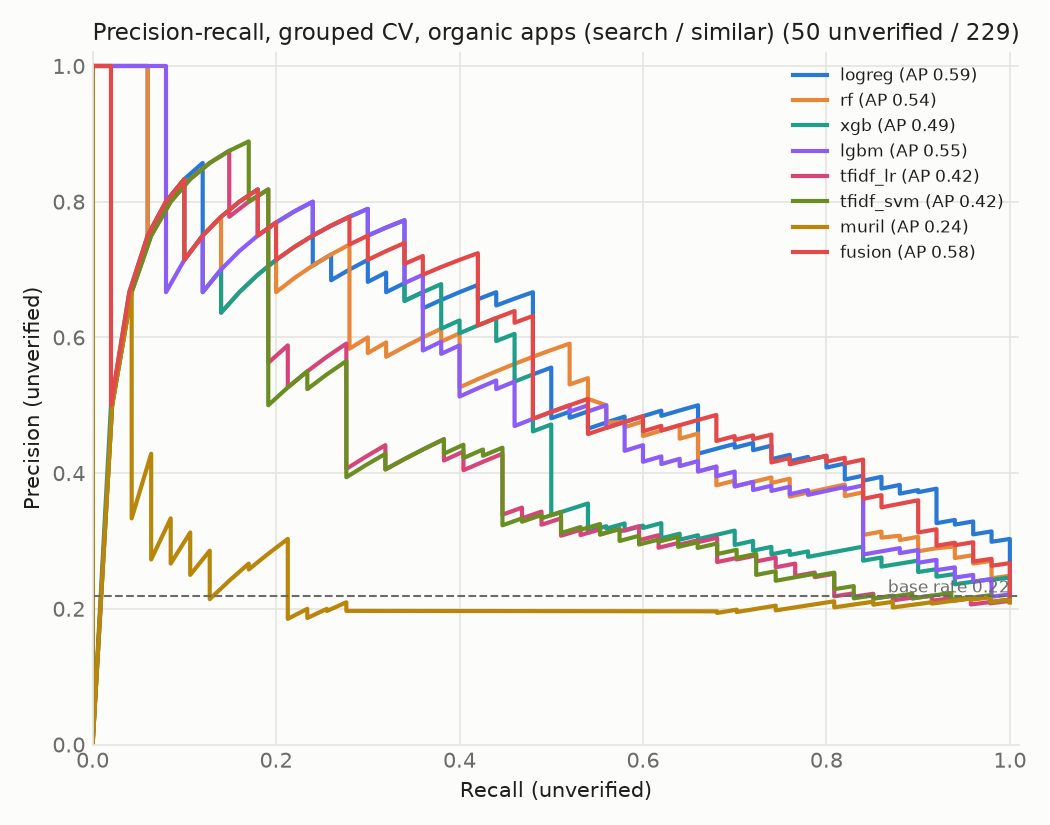

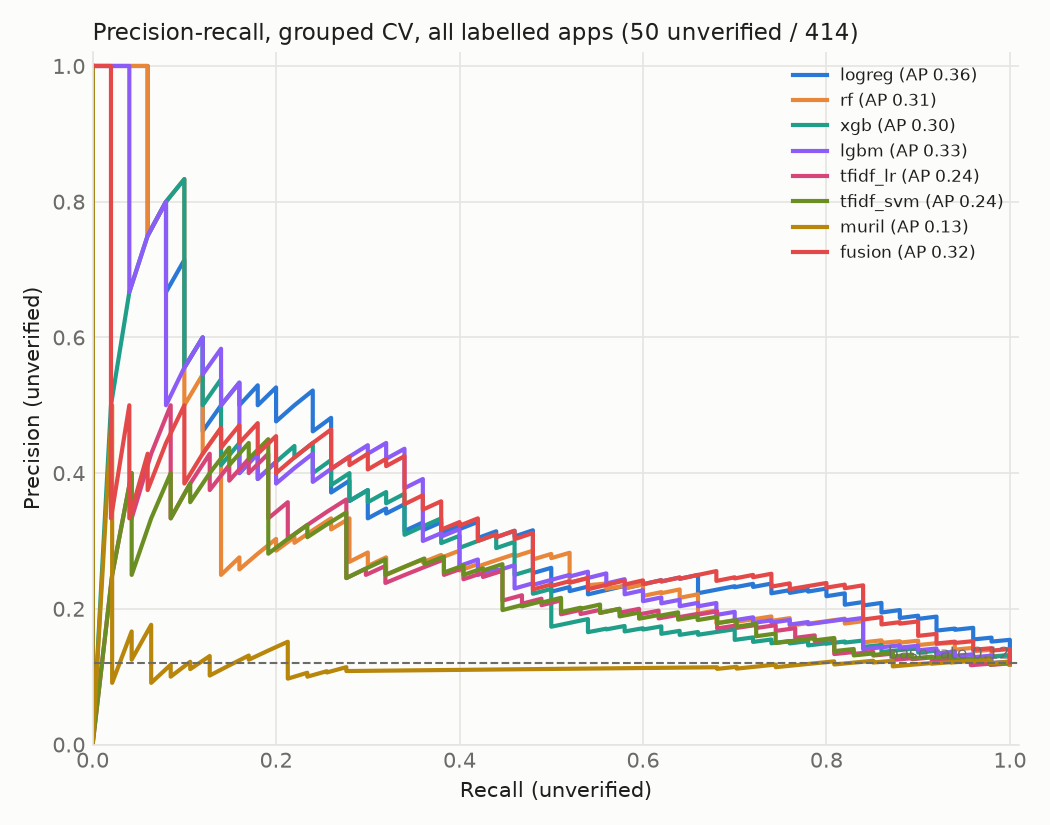

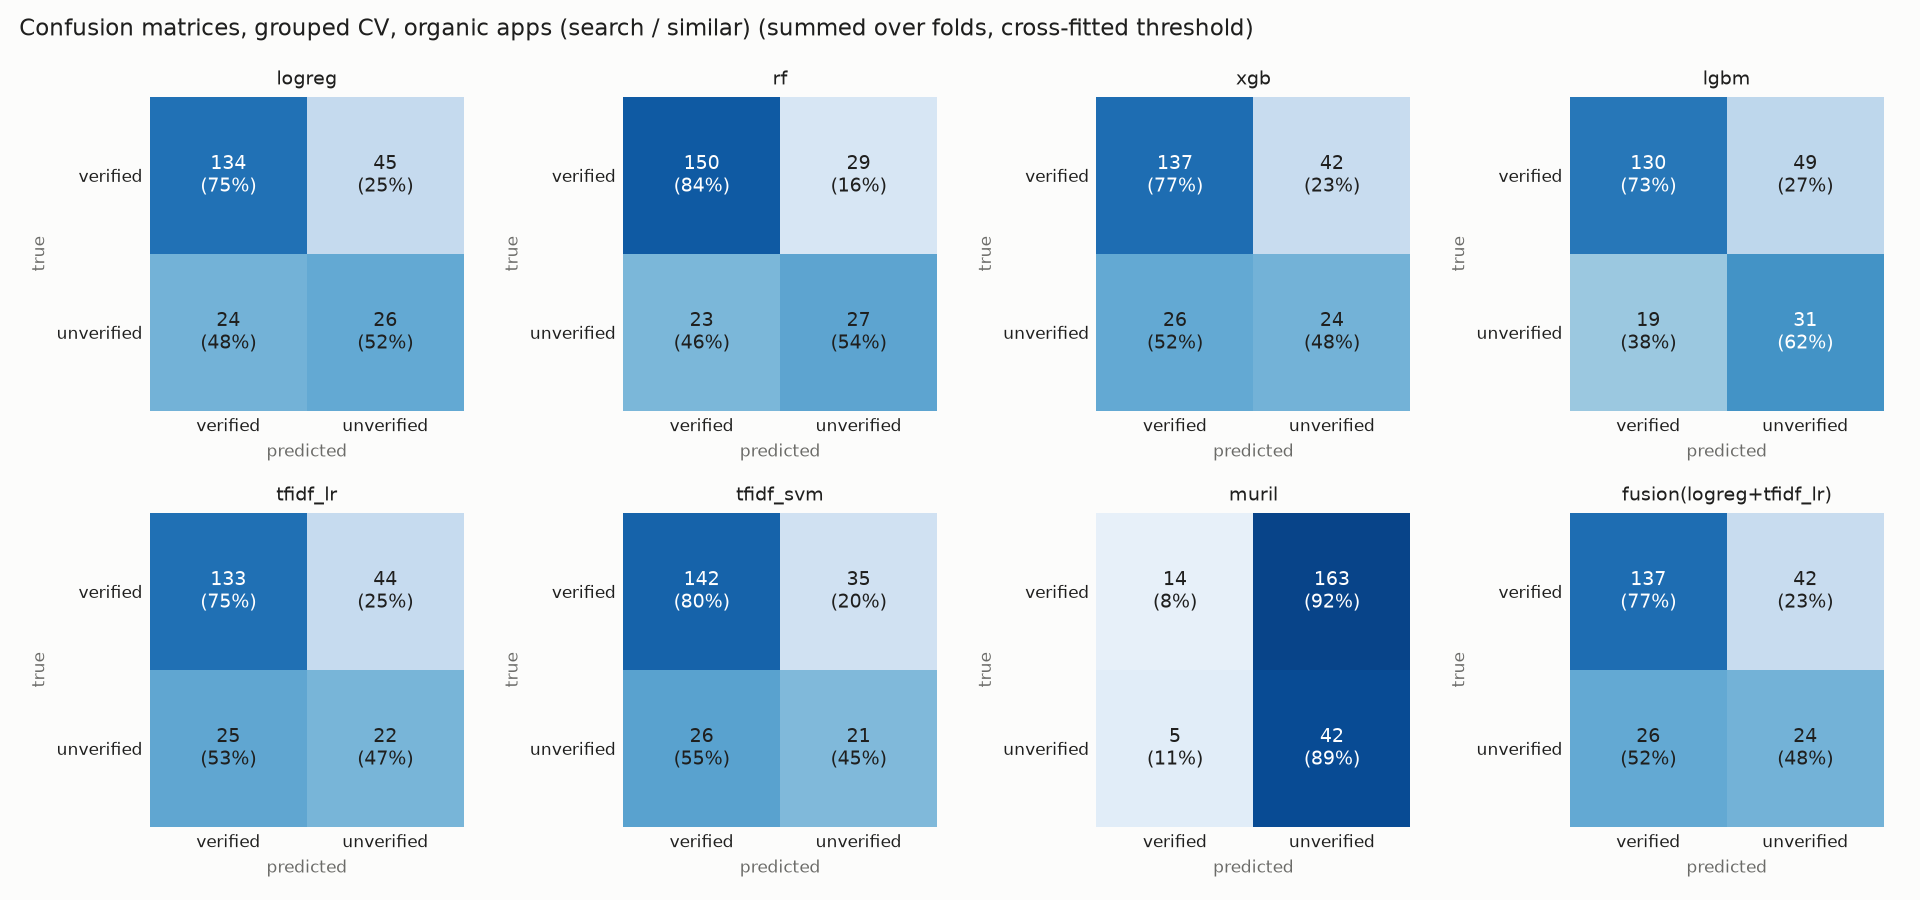

In [2]:
main = rx.exp_main(ds, N_ITER)
show(main, ["family"])
display(Markdown(f"**Headline subset: {rx.HEADLINE}**"))
display(Image(str(path("results", "figures", "pr_curves_grouped.png"))))           # headline subset
display(Image(str(path("results", "figures", f"pr_curves_grouped_{rx.OTHER}.png"))))  # for comparison
display(Image(str(path("results", "figures", "confusion_grouped.png"))))

## 2. Temporal hold-out
Train on apps released before the cut-off, test on later ones (best 3 single models from the main comparison).

In [3]:
show(rx.exp_temporal(ds, N_ITER), ["cutoff", "n_pos_total"])

23:46:17 INFO splits: temporal cut-off 2025-11-20: train 306 (29 pos), test 103 (21 pos)



=== temporal_holdout.csv ===
 model  subset  n_pos_total  base_rate pr_auc roc_auc recall_at_5fpr precision recall    f1 macro_f1
logreg organic           21      0.488  0.773   0.719          0.333     0.818  0.429 0.562    0.652
    rf organic           21      0.488  0.865   0.879          0.667     0.000  0.000 0.000    0.338
  lgbm organic           21      0.488  0.738   0.740          0.381     0.000  0.000 0.000    0.338
logreg     all           21      0.204  0.406   0.642          0.190     0.375  0.429 0.400    0.616
    rf     all           21      0.204  0.530   0.787          0.286     0.000  0.000 0.000    0.443
  lgbm     all           21      0.204  0.437   0.705          0.286     0.000  0.000 0.000    0.443


,cutoff,n_pos_total,model,subset,base_rate,pr_auc,roc_auc,recall_at_5fpr,precision,recall,f1,macro_f1
1,2025-11-20,21,logreg,organic,0.488,0.773,0.719,0.333,0.818,0.429,0.562,0.652
3,2025-11-20,21,rf,organic,0.488,0.865,0.879,0.667,0.000,0.000,0.000,0.338
5,2025-11-20,21,lgbm,organic,0.488,0.738,0.740,0.381,0.000,0.000,0.000,0.338
0,2025-11-20,21,logreg,all,0.204,0.406,0.642,0.190,0.375,0.429,0.400,0.616
2,2025-11-20,21,rf,all,0.204,0.530,0.787,0.286,0.000,0.000,0.000,0.443
4,2025-11-20,21,lgbm,all,0.204,0.437,0.705,0.286,0.000,0.000,0.000,0.443


## 3. Ablation

23:46:32 INFO tabular: logreg/weights fold 0: inner AP 0.454


23:46:32 INFO tabular: logreg/weights fold 1: inner AP 0.321


23:46:33 INFO tabular: logreg/weights fold 2: inner AP 0.519


23:46:33 INFO tabular: logreg/weights fold 3: inner AP 0.430


23:46:34 INFO tabular: logreg/weights fold 4: inner AP 0.392


...

23:46:45 INFO tabular: logreg/weights fold 2: inner AP 0.460


23:46:45 INFO tabular: logreg/weights fold 3: inner AP 0.383


23:46:46 INFO tabular: logreg/weights fold 4: inner AP 0.369



=== ablation.csv ===
              model  subset  family  n_pos_total  base_rate        pr_auc       roc_auc recall_at_5fpr     precision        recall            f1      macro_f1
        logreg-none organic tabular           50      0.218 0.648 ± 0.042 0.849 ± 0.033  0.400 ± 0.224 0.453 ± 0.148 0.520 ± 0.217 0.433 ± 0.028 0.612 ± 0.059
   logreg-developer organic tabular           50      0.218 0.641 ± 0.036 0.845 ± 0.062  0.400 ± 0.173 0.544 ± 0.095 0.700 ± 0.212 0.592 ± 0.084 0.728 ± 0.052
logreg-listing_text organic tabular           50      0.218 0.626 ± 0.133 0.820 ± 0.069  0.300 ± 0.255 0.383 ± 0.238 0.520 ± 0.335 0.427 ± 0.252 0.633 ± 0.127
    logreg-metadata organic tabular           50      0.218 0.652 ± 0.081 0.859 ± 0.060  0.360 ± 0.219 0.488 ± 0.162 0.600 ± 0.332 0.498 ± 0.211 0.673 ± 0.115
 logreg-permissions organic tabular           50      0.218 0.569 ± 0.122 0.766 ± 0.124  0.280 ± 0.130 0.368 ± 0.093 0.720 ± 0.192 0.479 ± 0.096 0.611 ± 0.076
 logreg-review_text orga

,dropped_group,model,subset,base_rate,pr_auc,roc_auc,recall_at_5fpr,precision,recall,f1,macro_f1
1,none,logreg-none,organic,0.218,0.648 ± 0.042,0.849 ± 0.033,0.400 ± 0.224,0.453 ± 0.148,0.520 ± 0.217,0.433 ± 0.028,0.612 ± 0.059
3,developer,logreg-developer,organic,0.218,0.641 ± 0.036,0.845 ± 0.062,0.400 ± 0.173,0.544 ± 0.095,0.700 ± 0.212,0.592 ± 0.084,0.728 ± 0.052
5,listing_text,logreg-listing_text,organic,0.218,0.626 ± 0.133,0.820 ± 0.069,0.300 ± 0.255,0.383 ± 0.238,0.520 ± 0.335,0.427 ± 0.252,0.633 ± 0.127
7,metadata,logreg-metadata,organic,0.218,0.652 ± 0.081,0.859 ± 0.060,0.360 ± 0.219,0.488 ± 0.162,0.600 ± 0.332,0.498 ± 0.211,0.673 ± 0.115
9,permissions,logreg-permissions,organic,0.218,0.569 ± 0.122,0.766 ± 0.124,0.280 ± 0.130,0.368 ± 0.093,0.720 ± 0.192,0.479 ± 0.096,0.611 ± 0.076
11,review_text,logreg-review_text,organic,0.218,0.603 ± 0.045,0.815 ± 0.073,0.300 ± 0.187,0.436 ± 0.104,0.740 ± 0.230,0.527 ± 0.096,0.658 ± 0.080
0,none,logreg-none,all,0.121,0.425 ± 0.124,0.782 ± 0.063,0.280 ± 0.130,0.223 ± 0.063,0.440 ± 0.219,0.280 ± 0.065,0.551 ± 0.070
2,developer,logreg-developer,all,0.121,0.399 ± 0.071,0.782 ± 0.079,0.200 ± 0.100,0.288 ± 0.078,0.520 ± 0.239,0.349 ± 0.092,0.605 ± 0.049
4,listing_text,logreg-listing_text,all,0.121,0.384 ± 0.133,0.738 ± 0.091,0.240 ± 0.207,0.341 ± 0.217,0.340 ± 0.207,0.339 ± 0.209,0.628 ± 0.111
6,metadata,logreg-metadata,all,0.121,0.424 ± 0.141,0.799 ± 0.081,0.280 ± 0.179,0.211 ± 0.076,0.500 ± 0.292,0.289 ± 0.116,0.559 ± 0.051


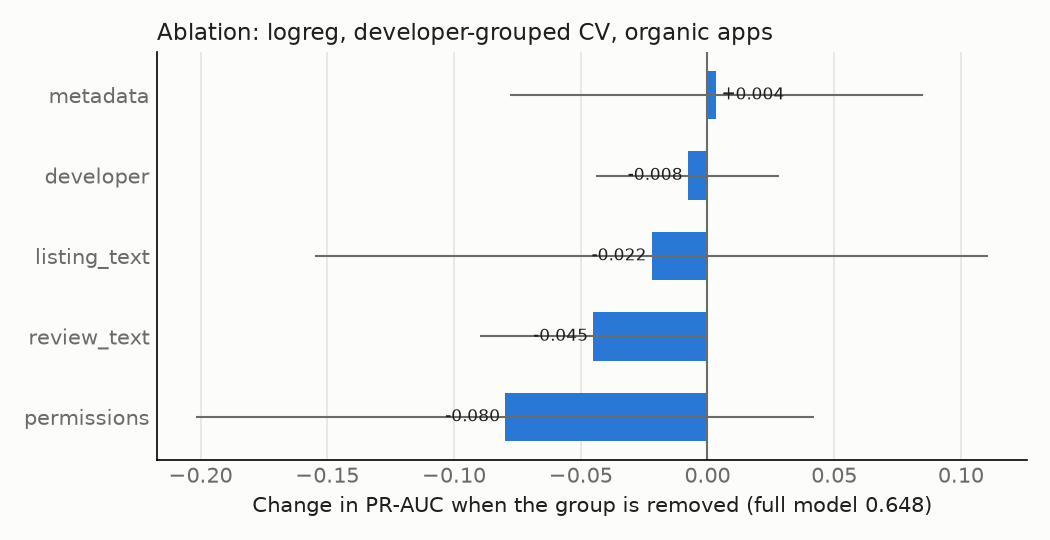

In [4]:
show(rx.exp_ablation(ds, N_ITER), ["dropped_group"])
display(Image(str(path("results", "figures", "ablation.png"))))

## 4. Early detection (first 14 days)
Snapshot-only metadata (installs, ratings, age, update date, developer counts) is dropped and reviews are limited to each app's first 14 days. Reviews were collected newest-first, so only apps released recently have early reviews (`docs/deviations.md` #13).

In [5]:
show(rx.exp_early(ds, N_ITER), ["features"])

23:46:46 INFO splits: dataset features_early14: 414 apps, 50 unverified, 366 developers, 40 features


23:46:47 INFO tabular: logreg/weights fold 0: inner AP 0.454


23:46:47 INFO tabular: logreg/weights fold 1: inner AP 0.321


23:46:48 INFO tabular: logreg/weights fold 2: inner AP 0.519


23:46:48 INFO tabular: logreg/weights fold 3: inner AP 0.430


...

23:46:50 INFO tabular: logreg/weights fold 2: inner AP 0.370


23:46:51 INFO tabular: logreg/weights fold 3: inner AP 0.376


23:46:51 INFO tabular: logreg/weights fold 4: inner AP 0.378



=== early_detection.csv ===
         model  subset  family  n_pos_total  base_rate        pr_auc       roc_auc recall_at_5fpr     precision        recall            f1      macro_f1
   logreg-full organic tabular           50      0.218 0.648 ± 0.042 0.849 ± 0.033  0.400 ± 0.224 0.453 ± 0.148 0.520 ± 0.217 0.433 ± 0.028 0.612 ± 0.059
logreg-early14 organic tabular           50      0.218 0.623 ± 0.117 0.835 ± 0.048  0.280 ± 0.192 0.483 ± 0.131 0.700 ± 0.200 0.540 ± 0.065 0.677 ± 0.058
   logreg-full     all tabular           50      0.121 0.425 ± 0.124 0.782 ± 0.063  0.280 ± 0.130 0.223 ± 0.063 0.440 ± 0.219 0.280 ± 0.065 0.551 ± 0.070
logreg-early14     all tabular           50      0.121 0.329 ± 0.124 0.752 ± 0.037  0.160 ± 0.182 0.237 ± 0.033 0.540 ± 0.241 0.314 ± 0.046 0.566 ± 0.046


,features,model,subset,base_rate,pr_auc,roc_auc,recall_at_5fpr,precision,recall,f1,macro_f1
1,full,logreg-full,organic,0.218,0.648 ± 0.042,0.849 ± 0.033,0.400 ± 0.224,0.453 ± 0.148,0.520 ± 0.217,0.433 ± 0.028,0.612 ± 0.059
3,early14,logreg-early14,organic,0.218,0.623 ± 0.117,0.835 ± 0.048,0.280 ± 0.192,0.483 ± 0.131,0.700 ± 0.200,0.540 ± 0.065,0.677 ± 0.058
0,full,logreg-full,all,0.121,0.425 ± 0.124,0.782 ± 0.063,0.280 ± 0.130,0.223 ± 0.063,0.440 ± 0.219,0.280 ± 0.065,0.551 ± 0.070
2,early14,logreg-early14,all,0.121,0.329 ± 0.124,0.752 ± 0.037,0.160 ± 0.182,0.237 ± 0.033,0.540 ± 0.241,0.314 ± 0.046,0.566 ± 0.046


## 5. Class weights vs SMOTE

In [6]:
show(rx.exp_smote(ds, N_ITER), ["imbalance"])

23:46:52 INFO tabular: logreg/weights fold 0: inner AP 0.454


23:46:52 INFO tabular: logreg/weights fold 1: inner AP 0.321


23:46:53 INFO tabular: logreg/weights fold 2: inner AP 0.519


23:46:53 INFO tabular: logreg/weights fold 3: inner AP 0.430


23:46:54 INFO tabular: logreg/weights fold 4: inner AP 0.392


...

23:49:49 INFO tabular: lgbm/smote fold 2: inner AP 0.527


23:49:51 INFO tabular: lgbm/smote fold 3: inner AP 0.464


23:49:53 INFO tabular: lgbm/smote fold 4: inner AP 0.394



=== imbalance_weights_vs_smote.csv ===
         model  subset  family  n_pos_total  base_rate        pr_auc       roc_auc recall_at_5fpr     precision        recall            f1      macro_f1
logreg-weights organic tabular           50      0.218 0.648 ± 0.042 0.849 ± 0.033  0.400 ± 0.224 0.453 ± 0.148 0.520 ± 0.217 0.433 ± 0.028 0.612 ± 0.059
  logreg-smote organic tabular           50      0.218 0.630 ± 0.118 0.809 ± 0.106  0.320 ± 0.164 0.463 ± 0.087 0.480 ± 0.259 0.441 ± 0.134 0.643 ± 0.066
    rf-weights organic tabular           50      0.218 0.583 ± 0.056 0.803 ± 0.070  0.340 ± 0.055 0.535 ± 0.126 0.540 ± 0.230 0.495 ± 0.128 0.671 ± 0.074
      rf-smote organic tabular           50      0.218 0.645 ± 0.132 0.846 ± 0.068  0.460 ± 0.241 0.482 ± 0.081 0.580 ± 0.277 0.507 ± 0.168 0.680 ± 0.090
   xgb-weights organic tabular           50      0.218 0.555 ± 0.097 0.790 ± 0.078  0.420 ± 0.164 0.544 ± 0.181 0.480 ± 0.311 0.422 ± 0.090 0.565 ± 0.216
     xgb-smote organic tabular      

,imbalance,model,subset,base_rate,pr_auc,roc_auc,recall_at_5fpr,precision,recall,f1,macro_f1
1,weights,logreg-weights,organic,0.218,0.648 ± 0.042,0.849 ± 0.033,0.400 ± 0.224,0.453 ± 0.148,0.520 ± 0.217,0.433 ± 0.028,0.612 ± 0.059
3,smote,logreg-smote,organic,0.218,0.630 ± 0.118,0.809 ± 0.106,0.320 ± 0.164,0.463 ± 0.087,0.480 ± 0.259,0.441 ± 0.134,0.643 ± 0.066
5,weights,rf-weights,organic,0.218,0.583 ± 0.056,0.803 ± 0.070,0.340 ± 0.055,0.535 ± 0.126,0.540 ± 0.230,0.495 ± 0.128,0.671 ± 0.074
7,smote,rf-smote,organic,0.218,0.645 ± 0.132,0.846 ± 0.068,0.460 ± 0.241,0.482 ± 0.081,0.580 ± 0.277,0.507 ± 0.168,0.680 ± 0.090
9,weights,xgb-weights,organic,0.218,0.555 ± 0.097,0.790 ± 0.078,0.420 ± 0.164,0.544 ± 0.181,0.480 ± 0.311,0.422 ± 0.090,0.565 ± 0.216
11,smote,xgb-smote,organic,0.218,0.566 ± 0.131,0.812 ± 0.078,0.320 ± 0.249,0.682 ± 0.300,0.440 ± 0.321,0.411 ± 0.095,0.564 ± 0.229
13,weights,lgbm-weights,organic,0.218,0.567 ± 0.080,0.780 ± 0.079,0.360 ± 0.134,0.477 ± 0.177,0.620 ± 0.327,0.466 ± 0.081,0.613 ± 0.095
15,smote,lgbm-smote,organic,0.218,0.568 ± 0.054,0.804 ± 0.052,0.300 ± 0.122,0.672 ± 0.296,0.400 ± 0.339,0.364 ± 0.060,0.538 ± 0.213
0,weights,logreg-weights,all,0.121,0.425 ± 0.124,0.782 ± 0.063,0.280 ± 0.130,0.223 ± 0.063,0.440 ± 0.219,0.280 ± 0.065,0.551 ± 0.070
2,smote,logreg-smote,all,0.121,0.413 ± 0.109,0.758 ± 0.097,0.260 ± 0.152,0.324 ± 0.164,0.380 ± 0.249,0.317 ± 0.120,0.604 ± 0.064


## 6. Leakage: random vs developer-grouped CV
A positive gap (random > grouped) means random splits flatter the model by letting one developer's near-identical apps sit on both sides.

In [7]:
show(rx.exp_leakage(ds, N_ITER), ["split"])

23:49:53 INFO tabular: logreg/weights fold 0: inner AP 0.454


23:49:54 INFO tabular: logreg/weights fold 1: inner AP 0.321


23:49:54 INFO tabular: logreg/weights fold 2: inner AP 0.519


23:49:55 INFO tabular: logreg/weights fold 3: inner AP 0.430


23:49:55 INFO tabular: logreg/weights fold 4: inner AP 0.392


...

23:52:54 INFO tabular: lgbm/weights fold 2: inner AP 0.419


23:52:55 INFO tabular: lgbm/weights fold 3: inner AP 0.331


23:52:56 INFO tabular: lgbm/weights fold 4: inner AP 0.406



=== leakage_random_vs_grouped.csv ===
         model  subset  family  n_pos_total  base_rate        pr_auc       roc_auc recall_at_5fpr     precision        recall            f1      macro_f1
logreg-grouped organic tabular           50      0.218 0.648 ± 0.042 0.849 ± 0.033  0.400 ± 0.224 0.453 ± 0.148 0.520 ± 0.217 0.433 ± 0.028 0.612 ± 0.059
    rf-grouped organic tabular           50      0.218 0.583 ± 0.056 0.803 ± 0.070  0.340 ± 0.055 0.535 ± 0.126 0.540 ± 0.230 0.495 ± 0.128 0.671 ± 0.074
   xgb-grouped organic tabular           50      0.218 0.555 ± 0.097 0.790 ± 0.078  0.420 ± 0.164 0.544 ± 0.181 0.480 ± 0.311 0.422 ± 0.090 0.565 ± 0.216
  lgbm-grouped organic tabular           50      0.218 0.567 ± 0.080 0.780 ± 0.079  0.360 ± 0.134 0.477 ± 0.177 0.620 ± 0.327 0.466 ± 0.081 0.613 ± 0.095
 logreg-random organic tabular           50      0.218 0.700 ± 0.088 0.866 ± 0.077  0.440 ± 0.114 0.586 ± 0.094 0.700 ± 0.173 0.631 ± 0.116 0.758 ± 0.071
     rf-random organic tabular       

,split,model,subset,base_rate,pr_auc,roc_auc,recall_at_5fpr,precision,recall,f1,macro_f1
1,grouped,logreg-grouped,organic,0.218,0.648 ± 0.042,0.849 ± 0.033,0.400 ± 0.224,0.453 ± 0.148,0.520 ± 0.217,0.433 ± 0.028,0.612 ± 0.059
3,grouped,rf-grouped,organic,0.218,0.583 ± 0.056,0.803 ± 0.070,0.340 ± 0.055,0.535 ± 0.126,0.540 ± 0.230,0.495 ± 0.128,0.671 ± 0.074
5,grouped,xgb-grouped,organic,0.218,0.555 ± 0.097,0.790 ± 0.078,0.420 ± 0.164,0.544 ± 0.181,0.480 ± 0.311,0.422 ± 0.090,0.565 ± 0.216
7,grouped,lgbm-grouped,organic,0.218,0.567 ± 0.080,0.780 ± 0.079,0.360 ± 0.134,0.477 ± 0.177,0.620 ± 0.327,0.466 ± 0.081,0.613 ± 0.095
9,random,logreg-random,organic,0.218,0.700 ± 0.088,0.866 ± 0.077,0.440 ± 0.114,0.586 ± 0.094,0.700 ± 0.173,0.631 ± 0.116,0.758 ± 0.071
11,random,rf-random,organic,0.218,0.664 ± 0.118,0.814 ± 0.105,0.380 ± 0.192,0.467 ± 0.136,0.520 ± 0.228,0.458 ± 0.098,0.640 ± 0.061
13,random,xgb-random,organic,0.218,0.593 ± 0.131,0.774 ± 0.073,0.340 ± 0.230,0.467 ± 0.186,0.440 ± 0.321,0.375 ± 0.065,0.551 ± 0.161
15,random,lgbm-random,organic,0.218,0.638 ± 0.117,0.796 ± 0.073,0.400 ± 0.212,0.702 ± 0.189,0.460 ± 0.207,0.527 ± 0.160,0.713 ± 0.088
0,grouped,logreg-grouped,all,0.121,0.425 ± 0.124,0.782 ± 0.063,0.280 ± 0.130,0.223 ± 0.063,0.440 ± 0.219,0.280 ± 0.065,0.551 ± 0.070
2,grouped,rf-grouped,all,0.121,0.340 ± 0.081,0.724 ± 0.090,0.160 ± 0.114,0.280 ± 0.078,0.480 ± 0.179,0.342 ± 0.099,0.604 ± 0.060


## Run log
Every experiment above appended a row per model × split to `results/runs.csv`.

In [8]:
runs = pd.read_csv(path("results", "runs.csv"))
display(runs.tail(15)[["timestamp", "experiment", "model", "split", "pr_auc", "roc_auc", "recall_at_5fpr"]])

,timestamp,experiment,model,split,pr_auc,roc_auc,recall_at_5fpr
55,2026-10-10T23:49:55,leakage,logreg-grouped,grouped/organic,0.648320,0.848898,0.40
56,2026-10-10T23:51:04,leakage,rf-grouped,grouped/all,0.339623,0.724186,0.16
57,2026-10-10T23:51:04,leakage,rf-grouped,grouped/organic,0.583337,0.802856,0.34
58,2026-10-10T23:51:17,leakage,xgb-grouped,grouped/all,0.337442,0.726385,0.20
59,2026-10-10T23:51:17,leakage,xgb-grouped,grouped/organic,0.554895,0.790499,0.42
60,2026-10-10T23:51:24,leakage,lgbm-grouped,grouped/all,0.366037,0.718626,0.22
61,2026-10-10T23:51:24,leakage,lgbm-grouped,grouped/organic,0.566550,0.780497,0.36
62,2026-10-10T23:51:26,leakage,logreg-random,random/all,0.448047,0.801096,0.36
63,2026-10-10T23:51:26,leakage,logreg-random,random/organic,0.699569,0.866434,0.44
64,2026-10-10T23:52:37,leakage,rf-random,random/all,0.433560,0.748181,0.36
